# Week 11-12 · Dimensionality Reduction · Part 1: PCA

**Goal:** understand the intuition behind Principal Component Analysis (PCA), build it from scratch, then use it on real data.

## Why reduce dimensions?
Real datasets often have dozens or thousands of features. That causes:
- **Curse of dimensionality** – distances become less meaningful, models overfit.
- **Redundancy** – many features are correlated and carry the same information.
- **No way to visualise** anything above 3D.

## PCA intuition
PCA finds **new axes (principal components)** that are linear combinations of the original features such that:
1. **PC1** points in the direction of **maximum variance** in the data.
2. **PC2** is perpendicular (orthogonal) to PC1 and captures the most remaining variance, and so on.

Keeping only the first *k* components gives a compressed *k*-dimensional version that keeps as much information (variance) as possible.

**Steps:** standardise → covariance matrix → eigenvectors/eigenvalues → sort by eigenvalue → project.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
np.random.seed(42)

## 1. Toy example in 2D: see the principal components

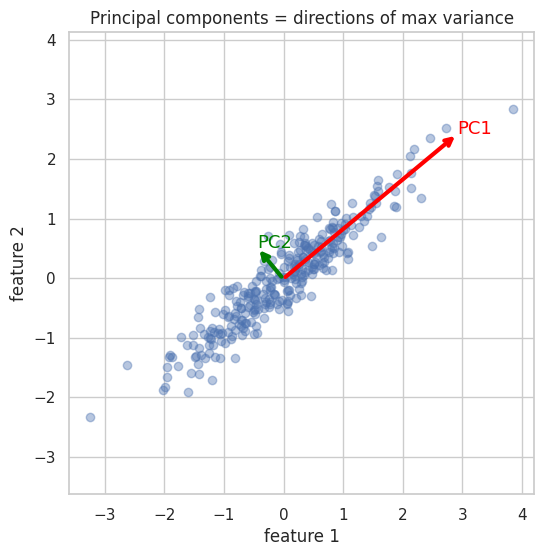

Explained variance ratio: [0.96963758 0.03036242]


In [2]:
# Correlated 2D data
n = 300
x = np.random.randn(n)
y = 0.8 * x + 0.3 * np.random.randn(n)
X2 = np.column_stack([x, y])

p2 = PCA(n_components=2).fit(X2)
center = X2.mean(axis=0)

plt.figure(figsize=(6,6))
plt.scatter(X2[:,0], X2[:,1], alpha=0.4)
for i, (vec, var) in enumerate(zip(p2.components_, p2.explained_variance_)):
    end = center + vec * np.sqrt(var) * 3
    plt.annotate("", xy=end, xytext=center, arrowprops=dict(arrowstyle="->", lw=3, color=["red","green"][i]))
    plt.text(*end, f"PC{i+1}", fontsize=13, color=["red","green"][i])
plt.axis("equal"); plt.title("Principal components = directions of max variance")
plt.xlabel("feature 1"); plt.ylabel("feature 2"); plt.show()
print("Explained variance ratio:", p2.explained_variance_ratio_)

PC1 (red) lies along the long axis of the cloud. Projecting onto PC1 alone keeps most of the information while going from 2D to 1D.

## 2. PCA from scratch (NumPy)
This shows PCA is just linear algebra on the covariance matrix.

In [3]:
def pca_from_scratch(X, k):
    Xc = X - X.mean(axis=0)                      # 1. centre
    cov = np.cov(Xc, rowvar=False)               # 2. covariance matrix
    eigvals, eigvecs = np.linalg.eigh(cov)       # 3. eigen-decomposition
    order = np.argsort(eigvals)[::-1]            # 4. sort descending
    eigvals, eigvecs = eigvals[order], eigvecs[:, order]
    W = eigvecs[:, :k]                           # 5. top-k eigenvectors
    return Xc @ W, eigvals / eigvals.sum(), W

Z_mine, evr_mine, _ = pca_from_scratch(X2, 2)
print("Scratch  EVR:", evr_mine)
print("sklearn  EVR:", p2.explained_variance_ratio_)

Scratch  EVR: [0.96963758 0.03036242]
sklearn  EVR: [0.96963758 0.03036242]


## 3. Real data: Wine dataset (13 chemical features, 3 wine classes)
Features are on very different scales (e.g. *proline* in hundreds, *hue* around 1), so **standardisation is essential** before PCA.

In [4]:
wine = pd.read_csv("../data/wine.csv")
print(wine.shape)
wine.head()

(178, 15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,target_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [5]:
X = wine.drop(columns=["target","target_name"])
y = wine["target_name"]

# What happens WITHOUT scaling?
raw = PCA(n_components=2).fit(X)
print("Without scaling, PC1 explains", round(raw.explained_variance_ratio_[0]*100,1), "% (dominated by 'proline')")
print(pd.Series(raw.components_[0], index=X.columns).abs().sort_values(ascending=False).head(3))

Without scaling, PC1 explains 99.8 % (dominated by 'proline')
proline              0.999823
magnesium            0.017868
alcalinity_of_ash    0.004671
dtype: float64


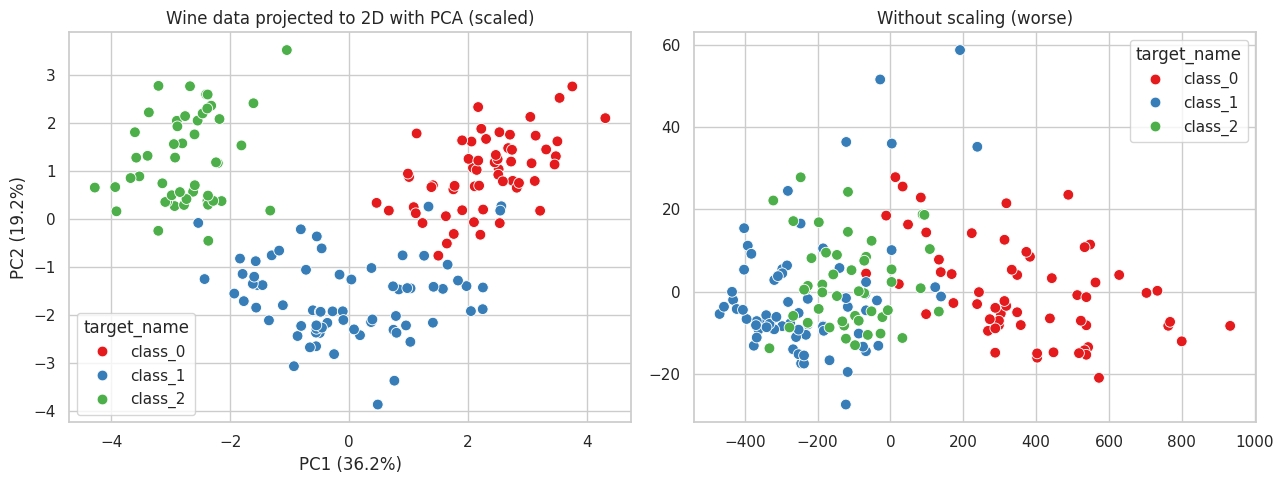

In [6]:
X_scaled = StandardScaler().fit_transform(X)
pca_w = PCA(n_components=2)
Z = pca_w.fit_transform(X_scaled)

fig, ax = plt.subplots(1, 2, figsize=(13,5))
sns.scatterplot(x=Z[:,0], y=Z[:,1], hue=y, palette="Set1", s=60, ax=ax[0])
ax[0].set_title("Wine data projected to 2D with PCA (scaled)")
ax[0].set_xlabel(f"PC1 ({pca_w.explained_variance_ratio_[0]*100:.1f}%)")
ax[0].set_ylabel(f"PC2 ({pca_w.explained_variance_ratio_[1]*100:.1f}%)")

Zr = raw.transform(X)
sns.scatterplot(x=Zr[:,0], y=Zr[:,1], hue=y, palette="Set1", s=60, ax=ax[1])
ax[1].set_title("Without scaling (worse)")
plt.tight_layout(); plt.show()

## 4. How many components? Scree plot & cumulative explained variance

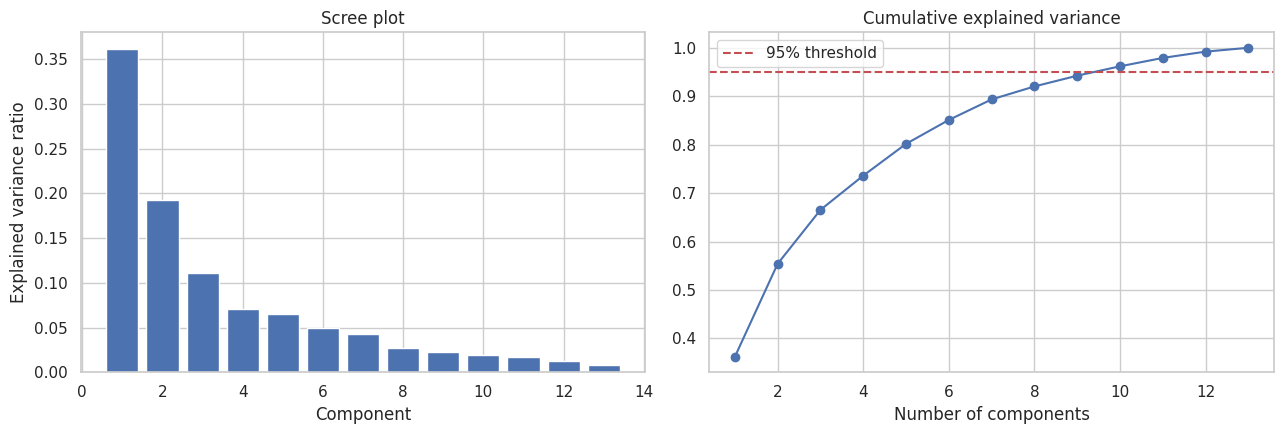

Components needed for 95% variance: 10


In [7]:
full = PCA().fit(X_scaled)
cum = np.cumsum(full.explained_variance_ratio_)

fig, ax = plt.subplots(1, 2, figsize=(13,4.5))
ax[0].bar(range(1, 14), full.explained_variance_ratio_)
ax[0].set_title("Scree plot"); ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance ratio")
ax[1].plot(range(1, 14), cum, marker="o")
ax[1].axhline(0.95, color="r", ls="--", label="95% threshold")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("Number of components"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Components needed for 95% variance:", np.argmax(cum >= 0.95) + 1)

## 5. Interpreting components: loadings
Loadings show how much each original feature contributes to each PC.

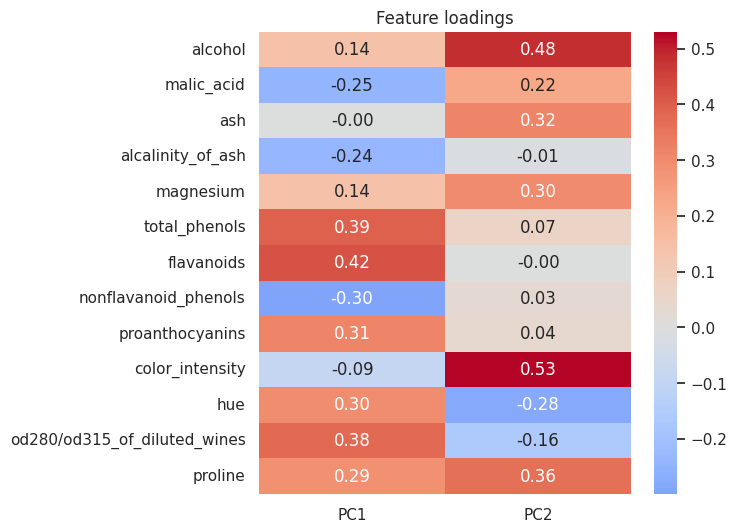

In [8]:
loadings = pd.DataFrame(pca_w.components_.T, index=X.columns, columns=["PC1","PC2"])
plt.figure(figsize=(6,6))
sns.heatmap(loadings, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Feature loadings"); plt.show()

## 6. Application: image compression with the Digits dataset
Each 8×8 image has 64 pixel features. How well can we reconstruct images from fewer components?

(1797, 64)


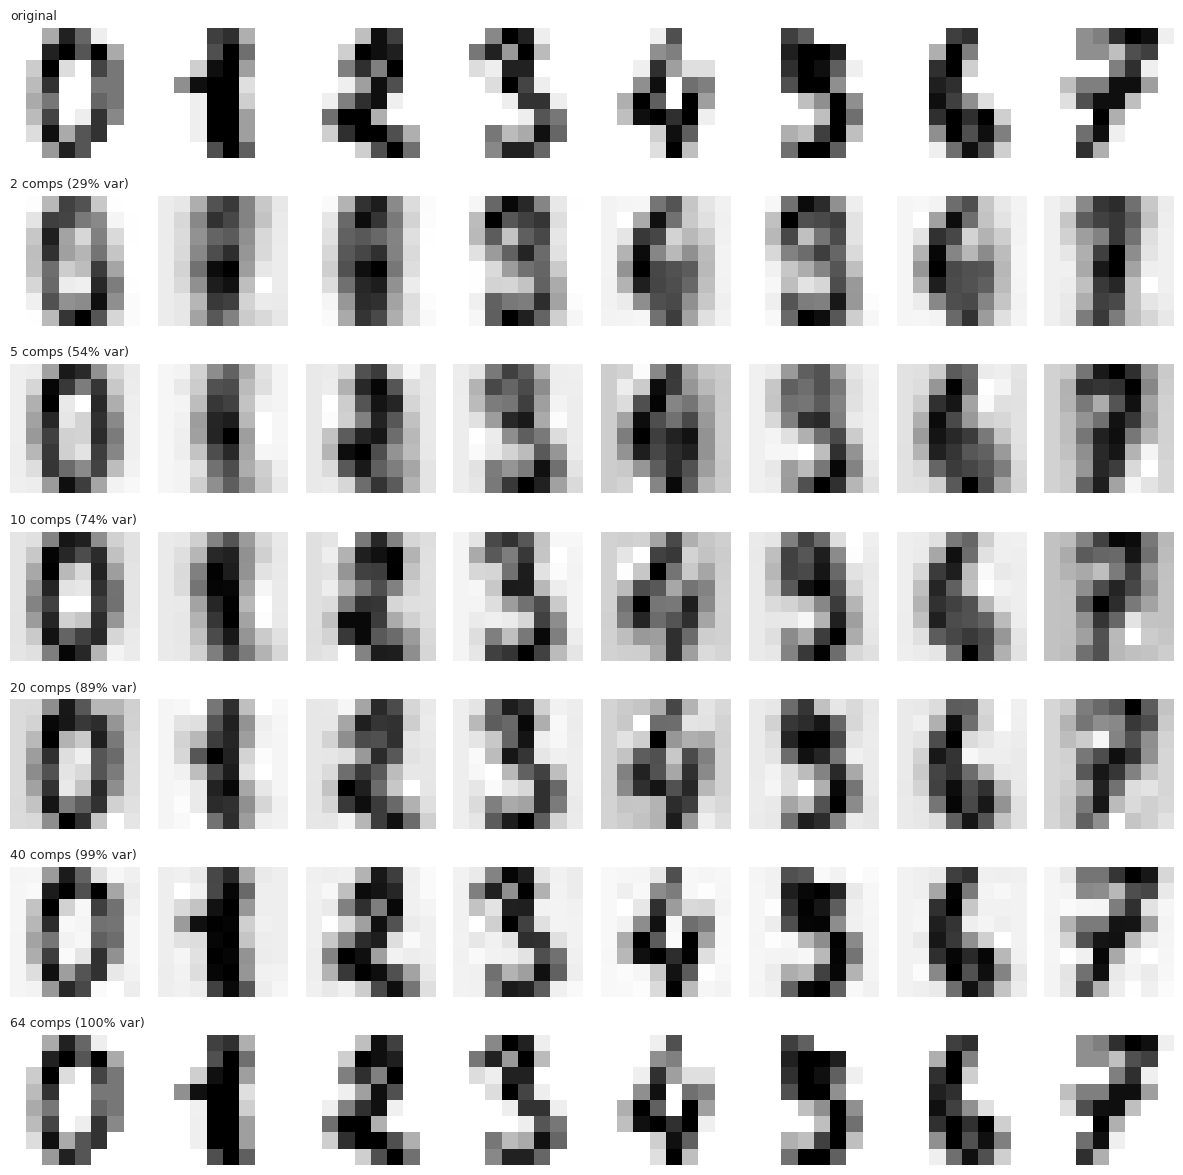

In [9]:
digits = pd.read_csv("../data/digits.csv")
Xd = digits.drop(columns="target").values
yd = digits["target"].values
print(Xd.shape)

ks = [2, 5, 10, 20, 40, 64]
fig, axes = plt.subplots(len(ks)+1, 8, figsize=(12, 12))
for j in range(8):
    axes[0, j].imshow(Xd[j].reshape(8,8), cmap="gray_r"); axes[0, j].axis("off")
axes[0,0].set_title("original", fontsize=9, loc="left")
for i, k in enumerate(ks, start=1):
    p = PCA(n_components=k).fit(Xd)
    rec = p.inverse_transform(p.transform(Xd))
    for j in range(8):
        axes[i, j].imshow(rec[j].reshape(8,8), cmap="gray_r"); axes[i, j].axis("off")
    axes[i,0].set_title(f"{k} comps ({p.explained_variance_ratio_.sum()*100:.0f}% var)", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

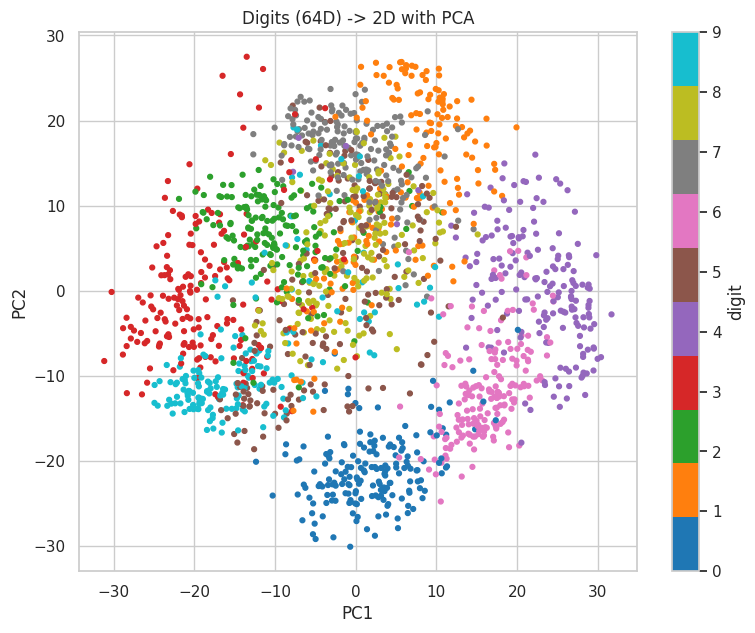

In [10]:
# 2D PCA of digits
Zd = PCA(n_components=2).fit_transform(Xd)
plt.figure(figsize=(9,7))
sc = plt.scatter(Zd[:,0], Zd[:,1], c=yd, cmap="tab10", s=12)
plt.colorbar(sc, label="digit"); plt.title("Digits (64D) -> 2D with PCA")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

PCA separates some digits (0 vs 1) but many classes overlap, because PCA is **linear** and only cares about variance. This motivates t-SNE (next notebook).

## 7. Application: PCA as preprocessing for a classifier

,n_components,test_accuracy
0,2,0.566667
1,5,0.820000
2,10,0.866667
3,20,0.955556
4,30,0.957778
5,64,0.968889


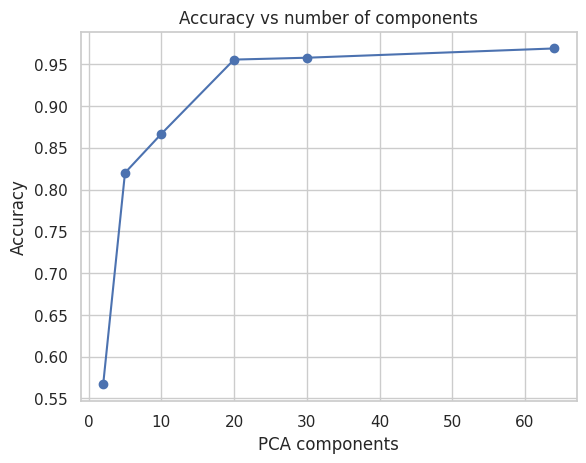

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.25, random_state=0, stratify=yd)
res = []
for k in [2, 5, 10, 20, 30, 64]:
    model = make_pipeline(StandardScaler(), PCA(n_components=k), LogisticRegression(max_iter=2000))
    model.fit(Xtr, ytr)
    res.append((k, model.score(Xte, yte)))
res = pd.DataFrame(res, columns=["n_components","test_accuracy"])
display(res)
plt.plot(res.n_components, res.test_accuracy, marker="o"); plt.xlabel("PCA components"); plt.ylabel("Accuracy")
plt.title("Accuracy vs number of components"); plt.show()

## Summary: PCA
| Aspect | PCA |
|---|---|
| Type | Linear, unsupervised |
| Preserves | Global structure / variance |
| Deterministic | Yes |
| Speed | Fast |
| Uses | Compression, noise removal, preprocessing, visualisation, removing multicollinearity |
| Limits | Misses non-linear structure; sensitive to feature scaling; components are hard to interpret |

## Exercises
1. Run PCA on the Wine data with 3 components and make a 3D scatter plot.
2. Which 2 features have the largest absolute loading on PC1?
3. Find the smallest number of components that gives ≥ 90% accuracy on Digits.